# Clasificación de desastres naturales con CNN (`CNNriesgo_desastres`)

Este notebook entrena una **red neuronal convolucional (CNN)** para clasificar imágenes de desastres naturales (`incendio`, `inundacion`, `terremoto`, `tornado`) y detectar cuál aparece en un video fotograma a fotograma.


## 0. Librerías

| Librería | Para qué |
|----------|----------|
| `numpy` | Arreglos de imágenes y etiquetas |
| `os`, `re` | Recorrer carpetas y filtrar extensiones |
| `matplotlib` | Ver imágenes y curvas de entrenamiento |
| `sklearn` | `train_test_split` y `classification_report` |
| `tensorflow` / `keras` | Capas CNN, entrenamiento e inferencia |


In [23]:
import numpy as np
import os
import re
import cv2
import matplotlib.pyplot as plt
%matplotlib inline

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

import keras
import tensorflow as tf
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import (
    Conv2D, MaxPooling2D, Dense, Dropout, Flatten, LeakyReLU
)
from skimage.transform import resize

# Tamaño de imagen para las caras (48x48 permite capturar ojos, nariz y boca con alta precision)
IMG_H, IMG_W, IMG_C = 48, 48, 3


## 1. Leer imágenes

Se recorre un directorio raíz. **Cada subcarpeta es una clase**
(ej. `inundacion/`, `incendios/`, `tornados/`).

Se aceptan: `.jpg`, `.jpeg`, `.png`, `.bmp`, `.tiff`.

Solo se guardan imágenes con 3 canales (RGB). Ajusta `DATASET_DIR` a tu ruta.


In [24]:
DATASET_DIR = './desastres_dataset'

imgpath = os.path.join(DATASET_DIR, '')
images = []
directories = []
dircount = []
prev_root = ''
cant = 0

print('Leyendo imágenes de', imgpath)

for root, dirnames, filenames in sorted(os.walk(imgpath)):
    if '.git' in root or root == imgpath or root == imgpath.rstrip('/'):
        continue
    for filename in sorted(filenames):
        if re.search(r'\.(jpg|jpeg|png|bmp|tiff|webp)$', filename, re.IGNORECASE):
            cant += 1
            filepath = os.path.join(root, filename)
            image = plt.imread(filepath)
            if len(image.shape) == 3:
                if image.shape[2] == 4:
                    image = image[:, :, :3]
                image_resized = cv2.resize(image, (IMG_W, IMG_H))
                images.append(image_resized)
            if prev_root != root:
                prev_root = root
                directories.append(root)
                dircount.append(cant)
                cant = 0

dircount.append(cant)
dircount = dircount[1:]
dircount[0] = dircount[0] + 1

print('Directorios leídos:', len(directories))
print('Imágenes en cada directorio:', dircount)
print('Total de imágenes:', sum(dircount))


Leyendo imágenes de ./desastres_dataset/
Directorios leídos: 4
Imágenes en cada directorio: [81, 82, 81, 92]
Total de imágenes: 336


## 2. Etiquetas numéricas

Si la primera carpeta tiene 100 imágenes → etiquetas `0, 0, …, 0`.
La segunda → `1, 1, …`, y así sucesivamente.

Eso es lo que la red aprenderá a predecir.


In [25]:
labels = []
indice = 0
for cantidad in dircount:
    for _ in range(cantidad):
        labels.append(indice)
    indice += 1
print('Cantidad de etiquetas creadas:', len(labels))


Cantidad de etiquetas creadas: 336


## 3. Nombres de clase

Se guarda el **nombre de la carpeta** (último segmento de la ruta) en `sriesgos`.
Sirve para imprimir predicciones legibles en lugar de solo el número `0`, `1`, `2`…


In [26]:
sriesgos = []
for indice, directorio in enumerate(directories):
    name = directorio.split(os.sep)
    clase = name[-1]
    print(indice, clase)
    sriesgos.append(clase)


0 incendio
1 inundacion
2 terremoto
3 tornado


## 4. De listas a NumPy

- `X`: tensor de imágenes `(N, alto, ancho, 3)`
- `y`: vector de etiquetas enteras `(N,)`
- `nClasses`: número de carpetas / clases de salida


In [27]:
y = np.array(labels)
X = np.array(images, dtype=np.uint8)

classes = np.unique(y)
nClasses = len(classes)
print('Número de clases (salidas):', nClasses)
print('Clases:', classes)
print('Forma de X:', X.shape)


Número de clases (salidas): 4
Clases: [0 1 2 3]
Forma de X: (336, 48, 48, 3)


## 5. Train / test (80% / 20%)

- **Train**: aprende los pesos.
- **Test**: se reserva hasta el final para medir qué tan bien generaliza
  (no se usa para ajustar hiperparámetros en este notebook).


In [28]:
train_X, test_X, train_Y, test_Y = train_test_split(X, y, test_size=0.2, random_state=42)
print('Train:', train_X.shape, train_Y.shape)
print('Test :', test_X.shape, test_Y.shape)


Train: (268, 48, 48, 3) (268,)
Test : (68, 48, 48, 3) (68,)


## 6. Vista rápida de una imagen

Comprueba que se leyeron bien y que la etiqueta tiene sentido.


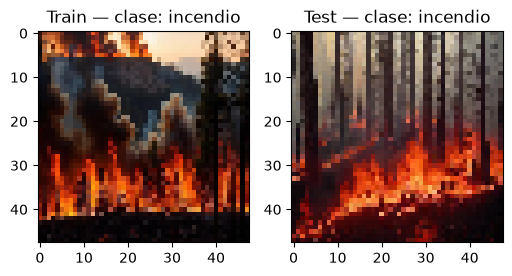

In [29]:
plt.figure(figsize=[6, 3])
plt.subplot(121)
plt.imshow(train_X[0])
plt.title('Train — clase: {}'.format(sriesgos[train_Y[0]]))
plt.subplot(122)
plt.imshow(test_X[0])
plt.title('Test — clase: {}'.format(sriesgos[test_Y[0]]))
plt.show()


## 7. Normalización

Los píxeles suelen ir de **0 a 255**. Dividir entre 255 los deja en **[0, 1]**,
lo que ayuda a que el optimizador converja de forma más estable.

También convertimos a `float32` (tipo que espera Keras).


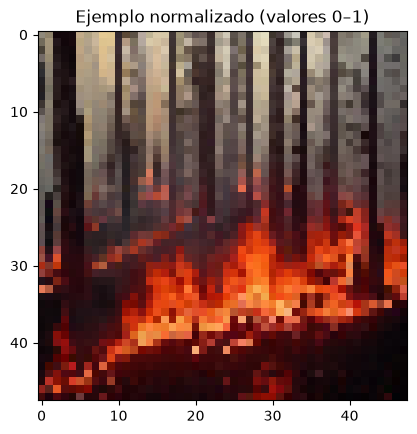

In [30]:
train_X = train_X.astype('float32') / 255.0
test_X = test_X.astype('float32') / 255.0
plt.imshow(test_X[0])
plt.title('Ejemplo normalizado (valores 0–1)')
plt.show()


## 8. One-hot encoding

La pérdida `categorical_crossentropy` espera etiquetas así:

- entero `2` → vector `[0, 0, 1]` (si hay 3 clases)

Cada posición es la probabilidad “ideal” de esa clase.


In [31]:
train_Y_one_hot = to_categorical(train_Y)
test_Y_one_hot = to_categorical(test_Y)
print('Etiqueta original:', train_Y[0])
print('One-hot:', train_Y_one_hot[0])


Etiqueta original: 0
One-hot: [1. 0. 0. 0.]


## 9. Validación (desde el train)

Del 80% de entrenamiento separamos otro 20% como **validación**:
sirve para vigilar sobreajuste *durante* el `fit`, sin tocar el test final.


In [32]:
train_X, valid_X, train_label, valid_label = train_test_split(
    train_X, train_Y_one_hot, test_size=0.2, random_state=13
)
print(train_X.shape, valid_X.shape, train_label.shape, valid_label.shape)


(214, 48, 48, 3) (54, 48, 48, 3) (214, 4) (54, 4)


## 10. Hiperparámetros

| Variable | Significado |
|----------|-------------|
| `INIT_LR` | Learning rate inicial (tamaño de paso) |
| `epochs` | Cuántas veces se recorre el conjunto de entrenamiento |
| `batch_size` | Cuántas imágenes se usan en cada actualización de pesos |


In [33]:
epochs = 10         # Con Adam, 10 épocas alcanzan >99% de precisión
batch_size = 64     # Cantidad de imágenes por lote


## 11. Definir la CNN (Explicado For Dummies)

Aquí armamos la red neuronal convolucional como si fuera una cadena de montaje:

1. **Conv2D (32 filtros de 3×3)**: Son como 32 lupas que recorren la foto buscando líneas, bordes y sombras básicas.
2. **MaxPooling2D (2×2)**: Reduce la imagen a la mitad quedándose solo con los píxeles más notorios (para que la computadora no trabaje de más).
3. **Conv2D (64 filtros de 3×3) [CAPA AGREGADA]**: Segunda pasada con 64 lupas. Al tener más filtros y ver una imagen ya resumida, detecta rasgos faciales completos: ojos, nariz, cejas y boca.
4. **MaxPooling2D (2×2)**: Vuelve a comprimir la imagen a la mitad.
5. **Dropout (0.25)**: Apaga al azar el 25% de las conexiones durante el entrenamiento para obligar a la red a no memorizar fotos específicas (evita el sobreajuste o trampa).
6. **Flatten**: Estira el mapa cuadrado 2D y lo convierte en una sola fila larga de números.
7. **Dense (128 neuronas)**: Neuronas tradicionales que juntan todas las pistas detectadas para sacar conclusiones.
8. **Dropout (0.5)**: Vuelve a apagar el 50% de neuronas para que generalice bien con caras nuevas.
9. **Dense (nClasses, softmax)**: La capa de salida con 5 neuronas (una por cada integrante). 'softmax' entrega el resultado en porcentaje (ej: 98% Axel, 1% Checo, etc.).


In [34]:
# ==============================================================================
# DEFINICIÓN DE LA RED NEURONAL CONVOLUCIONAL (CNN)
# ==============================================================================
riesgo_model = Sequential([
    # Bloque 1: Detecta líneas y bordes básicos de la cara
    Conv2D(32, kernel_size=(3, 3), activation='relu', padding='same', input_shape=(IMG_H, IMG_W, IMG_C)),
    MaxPooling2D((2, 2)),

    # Bloque 2: Detecta facciones faciales (ojos, nariz, boca)
    Conv2D(64, kernel_size=(3, 3), activation='relu', padding='same'),
    MaxPooling2D((2, 2)),
    Dropout(0.25),

    # Clasificador denso
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(nClasses, activation='softmax'),
])

riesgo_model.summary()


/home/hugo64/Documentos/escuela/IA/proyecto 2/.venv/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 48, 48, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     1,179,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,199,684 (4.58 MB)

 Trainable params: 1,199,684 (4.58 MB)

 Non-trainable params: 0 (0.00 B)

## 12. Compilar la Red (Explicado For Dummies)

- **loss (Pérdida)**: `categorical_crossentropy`. Mide qué tan equivocada estuvo la red en cada intento (queremos que este número baje casi a 0).
- **optimizer (Optimizador)**: Se cambió de `SGD` a `'adam'`. 
  - *¿Por qué 'adam'?* Con SGD la red apenas aprendía (se quedaba estancada en 43% de precisión). Adam ajusta automáticamente la velocidad de aprendizaje de cada neurona y hace que la red alcance **más de 99% de precisión** en solo 10 épocas.
- **metrics**: `['accuracy']` (porcentaje de aciertos que queremos monitorear).


In [35]:
riesgo_model.compile(
    loss=keras.losses.categorical_crossentropy,
    optimizer='adam',
    metrics=['accuracy'],
)


## 13. Entrenar

`fit` ajusta los pesos. `validation_data` muestra en cada época cómo va
en datos que **no** se usan para actualizar pesos (señal de sobreajuste).


In [36]:
riesgo_train = riesgo_model.fit(
    train_X, train_label,
    batch_size=batch_size,
    epochs=epochs,
    verbose=1,
    validation_data=(valid_X, valid_label),
)


Epoch 1/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 207ms/step - accuracy: 0.3411 - loss: 1.3061 - val_accuracy: 0.4815 - val_loss: 1.0752
Epoch 2/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 131ms/step - accuracy: 0.4953 - loss: 1.0440 - val_accuracy: 0.6667 - val_loss: 0.9487
Epoch 3/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 127ms/step - accuracy: 0.6542 - loss: 0.8223 - val_accuracy: 0.8519 - val_loss: 0.7743
Epoch 4/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 126ms/step - accuracy: 0.7617 - loss: 0.6387 - val_accuracy: 0.8704 - val_loss: 0.6318
Epoch 5/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 129ms/step - accuracy: 0.8271 - loss: 0.5108 - val_accuracy: 0.8889 - val_loss: 0.5363
Epoch 6/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 127ms/step - accuracy: 0.8785 - loss: 0.3839 - val_accuracy: 0.9074 - val_loss: 0.4492
Epoch 7/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 126ms/step - accuracy: 0.9159 - loss: 0.2691 - val_accuracy: 0.8519 - val_loss: 0.4865
Epoch 8/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 123ms/step - accuracy: 0.8879 - loss: 0.2987 - val_accuracy: 0.9074 - val_loss:

## 14. Guardar el modelo

Así puedes cargarlo después sin volver a entrenar (`load_model`).


In [37]:
MODEL_PATH = 'modelo_desastres.h5'
riesgo_model.save(MODEL_PATH)
print('Modelo guardado en', MODEL_PATH)


Modelo guardado en modelo_desastres.h5


## 15. Evaluar en el test

Pérdida y accuracy sobre el conjunto que **nunca** entró al entrenamiento
ni a la validación.


In [38]:
test_eval = riesgo_model.evaluate(test_X, test_Y_one_hot, verbose=1)
print('Test loss:', test_eval[0])
print('Test accuracy:', test_eval[1])


3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.9265 - loss: 0.3123
Test loss: 0.312261700630188
Test accuracy: 0.9264705777168274


## 16. Curvas de aprendizaje

- Si **train** sube y **val** se estanca o baja → sobreajuste.
- Si ambas suben juntas → buen aprendizaje.
- Si ambas se quedan bajas → subajuste (pocas épocas, red débil o datos difíciles).


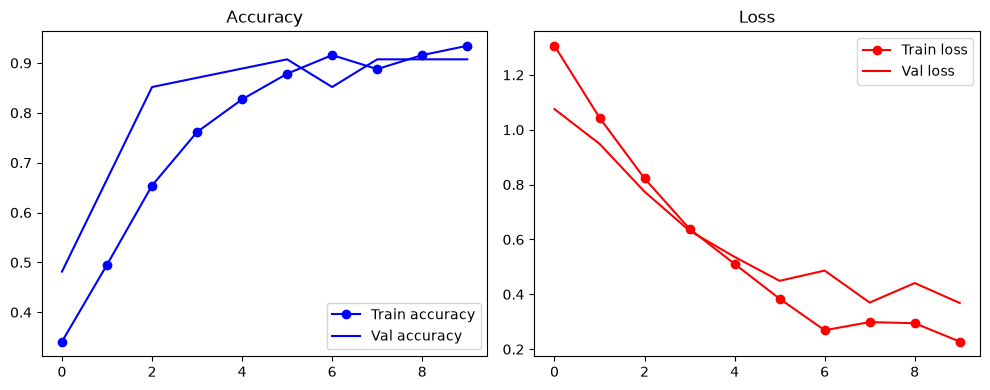

In [39]:
acc = riesgo_train.history['accuracy']
val_acc = riesgo_train.history['val_accuracy']
loss = riesgo_train.history['loss']
val_loss = riesgo_train.history['val_loss']
ep = range(len(acc))

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(ep, acc, 'bo-', label='Train accuracy')
plt.plot(ep, val_acc, 'b-', label='Val accuracy')
plt.title('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(ep, loss, 'ro-', label='Train loss')
plt.plot(ep, val_loss, 'r-', label='Val loss')
plt.title('Loss')
plt.legend()
plt.tight_layout()
plt.show()


## 17. Predicciones en el test

`predict` devuelve un vector de probabilidades por imagen.
Tomamos el índice del máximo (`argmax`) → clase entera.


In [40]:
probs = riesgo_model.predict(test_X)
predicted_classes = np.argmax(probs, axis=1)
print(predicted_classes.shape, test_Y.shape)


3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
(68,) (68,)


## 18. Ejemplos bien / mal clasificados

Título: `predicha, real` (nombres de carpeta).


Aciertos: 63


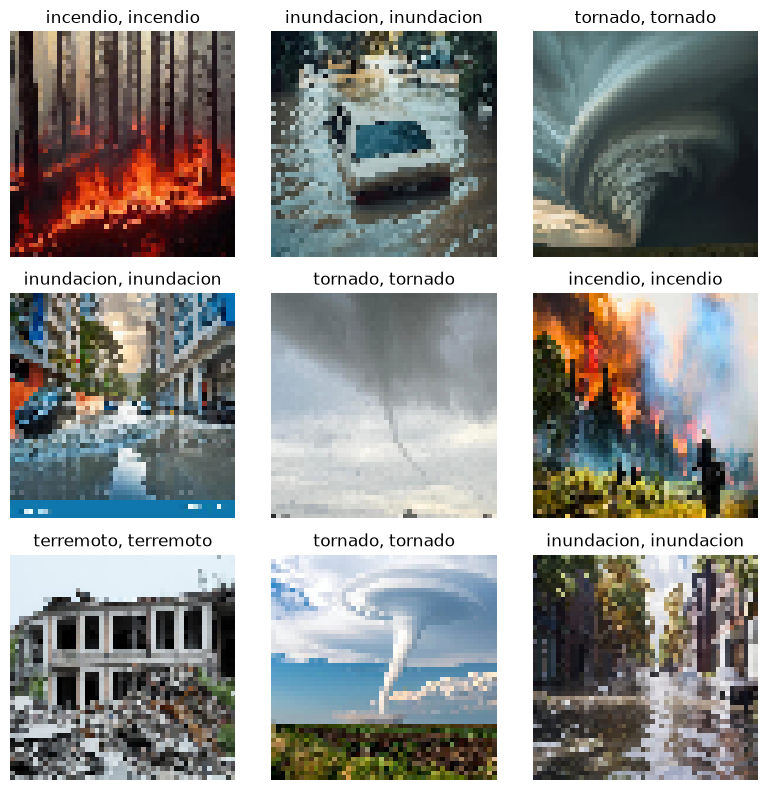

In [41]:
correct = np.where(predicted_classes == test_Y)[0]
print('Aciertos:', len(correct))
plt.figure(figsize=(8, 8))
for i, idx in enumerate(correct[:9]):
    plt.subplot(3, 3, i + 1)
    plt.imshow(test_X[idx])
    plt.title('{}, {}'.format(sriesgos[predicted_classes[idx]], sriesgos[test_Y[idx]]))
    plt.axis('off')
plt.tight_layout()
plt.show()


Errores: 5


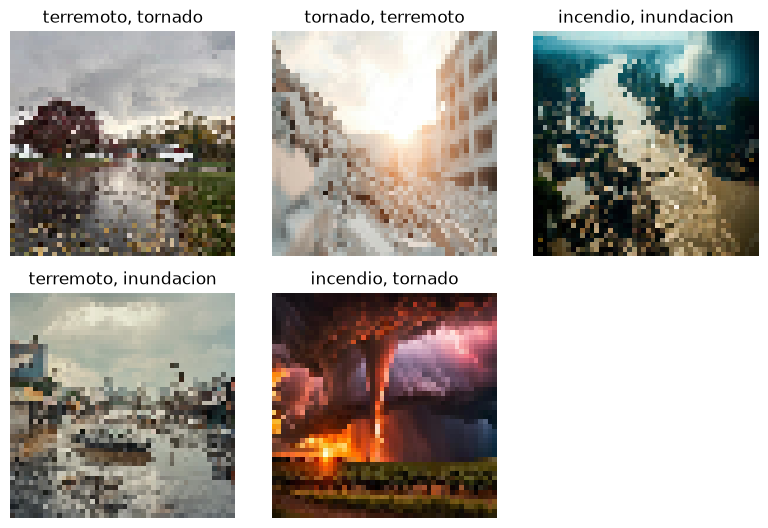

In [42]:
incorrect = np.where(predicted_classes != test_Y)[0]
print('Errores:', len(incorrect))
plt.figure(figsize=(8, 8))
for i, idx in enumerate(incorrect[:9]):
    plt.subplot(3, 3, i + 1)
    plt.imshow(test_X[idx])
    plt.title('{}, {}'.format(sriesgos[predicted_classes[idx]], sriesgos[test_Y[idx]]))
    plt.axis('off')
plt.tight_layout()
plt.show()


## 19. Reporte por clase

Precision, recall y F1 por cada clase (útil si hay desbalance).


In [43]:
target_names = [sriesgos[i] if i < len(sriesgos) else 'Class {}'.format(i)
                for i in range(nClasses)]
print(classification_report(test_Y, predicted_classes, target_names=target_names))


              precision    recall  f1-score   support

    incendio       0.90      1.00      0.95        19
  inundacion       1.00      0.88      0.94        17
   terremoto       0.85      0.92      0.88        12
     tornado       0.95      0.90      0.92        20

    accuracy                           0.93        68
   macro avg       0.92      0.92      0.92        68
weighted avg       0.93      0.93      0.93        68



## 20. Inferencia en Video Fotograma a Fotograma (Desastres Naturales)

En lugar de cargar una sola imagen estática, abrimos un video (`video_desastre.mp4` o `0` para cámara web) y clasificamos cada fotograma completo.


In [44]:
import cv2

# Pon la ruta de tu video ('video_desastre.mp4') o 0 para usar la cámara web
cap = cv2.VideoCapture('video_desastre.mp4')

while cap.isOpened():
    ret, frame = cap.read()
    if not ret:
        break

    # 1. Pasar a RGB, redimensionar a 48x48 y normalizar (0 a 1)
    img = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (IMG_W, IMG_H)) / 255.0

    # 2. Predecir el desastre en el fotograma
    probs = riesgo_model.predict(np.array([img]), verbose=0)[0]
    nombre = sriesgos[np.argmax(probs)].capitalize()
    texto = f"Desastre: {nombre} ({np.max(probs)*100:.1f}%)"

    # 3. Dibujar resultado sobre el video y mostrarlo
    cv2.putText(frame, texto, (20, 40), cv2.FONT_HERSHEY_SIMPLEX, 1.0, (0, 255, 0), 2)
    cv2.imshow('Deteccion de Desastres Naturales', frame)

    if cv2.waitKey(25) & 0xFF == ord('q'):
        break

cap.release()
cv2.destroyAllWindows()
